# SkySynth AI | SEC 302 Generative AI
Upload this notebook to Colab, choose **Runtime → Change runtime type → T4 GPU**, then choose **Runtime → Run all**. No companion files are needed. The first run downloads the three pretrained models. The Gradio demo is optional in the final cell.

Stable Diffusion 1.5 generates a clear base; SDEdit adds weather by partially noising and denoising that base. Matched variants share the same clear input, though editing can change objects or geometry.

In [ ]:
# Cell 1
# Keep Colab's preinstalled torch and torchvision matched to CUDA.
# We explicitly add/upgrade huggingface_hub to prevent FLAX import mismatches.
%pip install -q diffusers==0.35.2 transformers==4.56.2 huggingface_hub>=0.25.0 accelerate==1.10.1 gradio==5.49.1 ultralytics==8.3.203 'Pillow>=10' 'matplotlib>=3.8'

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
hf-gradio 0.4.1 requires gradio-client<3.0,>=2.0, but you have gradio-client 1.13.3 which is incompatible.
google-adk 2.7.1 requires pydantic<3,>=2.12, but you have pydantic 2.11.10 which is incompatible.
google-adk 2.7.1 requires starlette<2,>=1.3.1, but you have starlette 0.52.1 which is incompatible.
python-fasthtml 0.14.18 requires starlette>=1.0.1, but you have starlette 0.52.1 which is incompatible.
google-genai 2.12.1 requires pydantic<3.0.0,>=2.12.5, but you have pydantic 2.11.10 which is incompatible.


In [ ]:
# Cell 2
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from diffusers import (
    StableDiffusionPipeline,
    StableDiffusionImg2ImgPipeline,
    DPMSolverMultistepScheduler
)
import gradio as gr

# ── Device & dtype selection ──────────────────────────────────
# float16 halves VRAM usage on GPU; fallback to float32 on CPU
device = "cuda" if torch.cuda.is_available() else "cpu"
dtype  = torch.float16 if device == "cuda" else torch.float32

print(f"Device  : {device}")
print(f"Dtype   : {dtype}")
if device == "cuda":
    print(f"GPU     : {torch.cuda.get_device_name(0)}")
    vram_gb = torch.cuda.get_device_properties(0).total_memory / 1e9
    print(f"VRAM    : {vram_gb:.1f} GB")
else:
    print("WARNING: No GPU detected. Generation will be very slow on CPU.")



if not torch.cuda.is_available():
    raise RuntimeError("In Colab, choose Runtime > Change runtime type > T4 GPU.")
if tuple(map(int, torch.__version__.split("+")[0].split(".")[:2])) < (2, 6):
    raise RuntimeError("Use a current Colab runtime with PyTorch 2.6 or newer.")

In [ ]:
# Cell 3
# This downloads ~4 GB of model weights. Takes 5-10 minutes
# on first run; cached on disk for subsequent runs.

MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-v1-5"
print(f"Loading model: {MODEL_ID}")
print("Please wait — first run downloads ~4 GB of weights...\n")

# ── Load Text-to-Image pipeline ───────────────────────────────
txt2img_pipe = StableDiffusionPipeline.from_pretrained(
    MODEL_ID,
    torch_dtype=dtype,
    use_safetensors=True,
    **({"variant": "fp16"} if device == "cuda" else {}),
).to(device)

# ── Swap default PNDM scheduler → DPM-Solver++ ───────────────
# DPM-Solver++ lets us use a shorter denoising schedule for the demo.
txt2img_pipe.scheduler = DPMSolverMultistepScheduler.from_config(
    txt2img_pipe.scheduler.config
)

# ── Reuse weights for img2img pipeline ───────────────────────
# Passes shared model components (VAE, UNet, tokenizer, text encoder)
# so we do NOT download or store a second copy of the weights
img2img_pipe = StableDiffusionImg2ImgPipeline.from_pipe(txt2img_pipe)
img2img_pipe.scheduler = DPMSolverMultistepScheduler.from_config(txt2img_pipe.scheduler.config)

print("\nModels loaded successfully!")

In [ ]:
# Cell 4
# Each terrain entry is a descriptive phrase appended to the base prompt.
# More specific = better structural coherence in generated images.
TERRAIN_PROMPTS = {
    "Urban":        "dense urban city grid with buildings, roads, rooftops, and city blocks",
    "Forest":       "dense green forest canopy, treetops, woodland, lush tropical vegetation",
    "Desert":       "arid desert terrain with sand dunes, rocky outcrops, and minimal vegetation",
    "Coastal":      "coastal terrain with sandy beach, ocean shoreline, shallow turquoise water",
    "Agricultural": "agricultural farmland with crop field patterns, irrigation channels, rural patchwork",
    "Mountain":     "rugged mountain terrain with rocky peaks, steep slopes, and alpine valleys",
}

# Tuple format: (weather_prompt_fragment, img2img_strength)
# strength=0.0 → no img2img pass needed (clear weather = base image)
# Higher strengths add more noise before denoising.
# Higher strength = more weather effect, but risks losing terrain structure
WEATHER_PROMPTS = {
    "Clear":    ("clear sky, bright sunlight, sharp visibility, vivid colors",   0.00),
    "Foggy":    ("dense ground fog, pale gray haze fading distant terrain, low contrast", 0.63),
    "Rainy":    ("heavy rainfall, reflective wet ground, puddles, muted gray lighting", 0.67),
    "Night":    ("dark nighttime, deep shadows across the ground, isolated artificial lights", 0.75),
    "Overcast": ("heavily overcast, flat grey lighting, full cloud cover",        0.44),
    "Snowy":    ("snow covered landscape, white blanket of snow, winter scene",   0.57),
}

WEATHER_NEGATIVES = {
    "Foggy": "crystal-clear visibility, crisp distant detail, direct sunlight",
    "Rainy": "dry ground, bright sunshine, hard sun shadows",
    "Night": "daylight, sunlight, evenly lit terrain",
}

# Altitude phrases guide the model on perceived scale and detail level
ALTITUDE_PROMPTS = {
    "Low (100m)":    "very close low altitude drone view, fine ground detail visible",
    "Medium (400m)": "standard medium altitude drone view, moderate level of detail",
    "High (1000m)":  "high altitude aerial overview, large geographic area visible",
}

# Negative prompt: tokens the model steers AWAY from during generation
# These ensure aerial top-down perspective and photorealism
NEGATIVE_PROMPT = (
    "blurry, distorted, unrealistic, cartoon, painting, illustration, "
    "low quality, jpeg artifacts, watermark, text, logo, "
    "tilted view, sideways view, street level, ground level, "
    "fisheye, lens distortion, person, human, face"
)

In [ ]:
# Cell 5
def build_base_prompt(terrain: str, altitude: str) -> str:
    """
    Constructs the full text prompt for Stage 1 (txt2img).
    Always generates clear-weather base to preserve terrain structure.
    """
    terrain_desc  = TERRAIN_PROMPTS[terrain]
    altitude_desc = ALTITUDE_PROMPTS[altitude]

    return (
        f"photorealistic aerial drone photograph of {terrain_desc}, "
        f"clear weather, bright daylight, {altitude_desc}, "
        f"top-down bird's eye view, satellite imagery style, "
        f"8k resolution, ultra detailed, professional drone photography, "
        f"sharp focus, high dynamic range"
    )


def build_weather_prompt(terrain: str, weather: str, altitude: str) -> str:
    """
    Constructs the full text prompt for Stage 2 (img2img weather conditioning).
    Retains terrain context while adding weather semantics.
    """
    terrain_desc  = TERRAIN_PROMPTS[terrain]
    weather_desc, _ = WEATHER_PROMPTS[weather]
    altitude_desc = ALTITUDE_PROMPTS[altitude]

    return (
        f"{weather_desc}, top-down aerial drone photograph of {terrain_desc}, "
        f"{altitude_desc}"
    )

In [ ]:
# Cell 6
def generate_aerial_image(
    terrain       : str   = "Urban",
    weather       : str   = "Clear",
    altitude      : str   = "Medium (400m)",
    seed          : int   = -1,
    num_steps     : int   = 25,
    guidance_scale: float = 7.5,
) -> tuple[Image.Image, int]:
    """
    Two-stage SkySynth generation pipeline.

    Stage 1 — Text-to-Image (txt2img):
        A clean base aerial image is generated from terrain + altitude prompt.
        Uses the full reverse diffusion process (T → 0 timesteps).

    Stage 2 — SDEdit Weather Conditioning (img2img):
        The base image is encoded into latent space, partially noised to
        timestep t = strength × T, then denoised with a weather-conditioned
        prompt. This transfers weather semantics while preserving terrain
        structure from Stage 1.

        strength controls the trade-off:
            low  strength → subtle weather, strong terrain preservation
            high strength → dramatic weather, risk of terrain drift

    Args:
        terrain        : terrain category key
        weather        : weather category key
        altitude       : altitude category key
        seed           : RNG seed (-1 for random); same seed = same base image
        num_steps      : number of denoising steps (20-25 sufficient with DPM-Solver++)
        guidance_scale : CFG scale — higher = more prompt-adherent, less diverse

    Returns:
        (PIL.Image, seed_used)
    """
    # ── Seed handling ─────────────────────────────────────────
    if seed == -1:
        seed = torch.randint(0, 2**32 - 1, (1,)).item()
    base = generate_clear_base(terrain, altitude, seed, num_steps, guidance_scale)
    return apply_weather(base, terrain, weather, altitude, seed, num_steps, guidance_scale), seed


def generate_clear_base(terrain, altitude, seed, num_steps, guidance_scale):
    generator = torch.Generator(device=device).manual_seed(seed)

    # ── Stage 1: Base terrain generation ─────────────────────
    base_prompt = build_base_prompt(terrain, altitude)

    return txt2img_pipe(
        prompt           = base_prompt,
        negative_prompt  = NEGATIVE_PROMPT,
        num_inference_steps = num_steps,
        guidance_scale   = guidance_scale,
        generator        = generator,
        height           = 512,
        width            = 512,
    ).images[0]


def apply_weather(base_image, terrain, weather, altitude, seed, num_steps, guidance_scale):
    """Apply SDEdit to an existing clear image so all variants share that exact input."""
    if weather == "Clear":
        return base_image

    # ── Stage 2: Weather conditioning via SDEdit ──────────────
    _, strength = WEATHER_PROMPTS[weather]
    weather_prompt = build_weather_prompt(terrain, weather, altitude)
    negative_prompt = NEGATIVE_PROMPT
    if weather in WEATHER_NEGATIVES:
        negative_prompt += ", " + WEATHER_NEGATIVES[weather]

    # Reinitialise generator with same seed for determinism
    generator = torch.Generator(device=device).manual_seed(seed)

    return img2img_pipe(
        prompt           = weather_prompt,
        negative_prompt  = negative_prompt,
        image            = base_image,
        strength         = strength,
        num_inference_steps = num_steps,
        guidance_scale   = guidance_scale,
        generator        = generator,
    ).images[0]

In [ ]:
import numpy as np
from PIL import Image, ImageEnhance, ImageDraw
import random

def apply_geometry_preserving_weather(
    pil_img: Image.Image,
    weather: str,
    intensity: float = 0.5,
    seed: int = 42
) -> Image.Image:
    """
    Applies pure image-space filters to render weather without warping pixel geometry.
    All random offsets are seed-locked for absolute reproducibility.
    """
    if weather == "Clear" or intensity <= 0.0:
        return pil_img.copy()

    # Seed-lock generators
    np.random.seed(seed & 0xFFFFFFFF)
    random.seed(seed)

    img_arr = np.array(pil_img).astype(np.float32)
    h, w, c = img_arr.shape

    if weather == "Foggy":
        # Uniform haze model (not depth-dependent for pure bird's-eye views)
        haze_color = np.array([225.0, 228.0, 232.0], dtype=np.float32)
        blend_factor = intensity * 0.75
        foggy_arr = img_arr * (1.0 - blend_factor) + haze_color * blend_factor

        # Reduce saturation to mimic light scattering
        out_img = Image.fromarray(np.clip(foggy_arr, 0, 255).astype(np.uint8))
        enhancer = ImageEnhance.Color(out_img)
        return enhancer.enhance(1.0 - (intensity * 0.5))

    elif weather == "Rainy":
        # 1. Darken and reduce contrast
        dark_factor = 1.0 - (intensity * 0.35)
        dark_arr = img_arr * dark_factor
        out_img = Image.fromarray(np.clip(dark_arr, 0, 255).astype(np.uint8))

        # 2. Render subtle rain streaks
        draw_img = out_img.copy()
        draw = ImageDraw.Draw(draw_img)
        num_streaks = int(80 + intensity * 150)

        # Streaks angle, length and opacity are repeatable via seeded random
        angle = random.uniform(-15.0, -5.0)
        dx = np.sin(np.radians(angle))
        dy = np.cos(np.radians(angle))

        for _ in range(num_streaks):
            x1 = random.randint(0, w)
            y1 = random.randint(0, h)
            length = random.randint(10, 25)
            x2 = int(x1 + dx * length)
            y2 = int(y1 + dy * length)
            opacity = random.randint(30, 90)
            draw.line([(x1, y1), (x2, y2)], fill=(230, 240, 255, opacity), width=1)

        return Image.blend(out_img, draw_img, alpha=0.8)

    elif weather == "Night":
        # 1. Heavily suppress brightness
        brightness_factor = 0.18 + (1.0 - intensity) * 0.22
        bright_enhancer = ImageEnhance.Brightness(pil_img)
        night_base = bright_enhancer.enhance(brightness_factor)

        # 2. Apply a cool/blueish ambient tone
        night_arr = np.array(night_base).astype(np.float32)
        night_arr[:, :, 0] *= 0.82  # Red reduction
        night_arr[:, :, 1] *= 0.88  # Green reduction
        night_arr[:, :, 2] *= 1.15  # Blue boost
        night_arr = np.clip(night_arr, 0, 255).astype(np.uint8)
        return Image.fromarray(night_arr)

    return pil_img.copy()

### Optimization: Improving Accuracy & Structural Consistency
Below we create a refined configuration and generation pipeline to fine-tune the SDEdit `strength` and add custom guidance modifiers to improve weather fidelity without sacrificing base layout features.

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/16 [00:00<?, ?it/s]

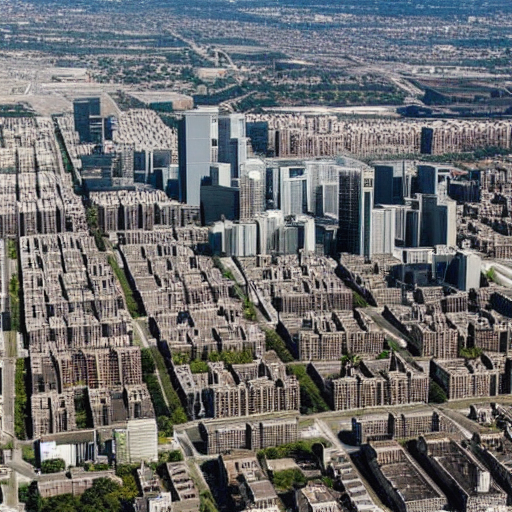

In [ ]:
# Let's optimize SDEdit strength mappings to balance weather intensity vs structural fidelity.
# We can also append detailed structural guidance to weather prompts to anchor the original layout.
import torch

# Ensure device and necessary variables from early cells are defined
device = "cuda" if torch.cuda.is_available() else "cpu"

# Ensure pipeline variables are defined in the session before running
if 'txt2img_pipe' not in globals() or 'img2img_pipe' not in globals():
    raise NameError(
        "Diffusion pipelines 'txt2img_pipe' and 'img2img_pipe' are not defined. "
        "Please ensure you have run Cell 3 (sky-03) in your current session to load the models."
    )

# Fallback local definitions in case earlier cells haven't run
if 'TERRAIN_PROMPTS' not in globals():
    TERRAIN_PROMPTS = {
        "Urban":        "dense urban city grid with buildings, roads, rooftops, and city blocks",
        "Forest":       "dense green forest canopy, treetops, woodland, lush tropical vegetation",
        "Desert":       "arid desert terrain with sand dunes, rocky outcrops, and minimal vegetation",
        "Coastal":      "coastal terrain with sandy beach, ocean shoreline, shallow turquoise water",
        "Agricultural": "agricultural farmland with crop field patterns, irrigation channels, rural patchwork",
        "Mountain":     "rugged mountain terrain with rocky peaks, steep slopes, and alpine valleys",
    }

if 'ALTITUDE_PROMPTS' not in globals():
    ALTITUDE_PROMPTS = {
        "Low (100m)":    "very close low altitude drone view, fine ground detail visible",
        "Medium (400m)": "standard medium altitude drone view, moderate level of detail",
        "High (1000m)":  "high altitude aerial overview, large geographic area visible",
    }

if 'WEATHER_NEGATIVES' not in globals():
    WEATHER_NEGATIVES = {
        "Foggy": "crystal-clear visibility, crisp distant detail, direct sunlight",
        "Rainy": "dry ground, bright sunshine, hard sun shadows",
        "Night": "daylight, sunlight, evenly lit terrain",
    }

if 'NEGATIVE_PROMPT' not in globals():
    NEGATIVE_PROMPT = (
        "blurry, distorted, unrealistic, cartoon, painting, illustration, "
        "low quality, jpeg artifacts, watermark, text, logo, "
        "tilted view, sideways view, street level, ground level, "
        "fisheye, lens distortion, person, human, face"
    )

if 'build_base_prompt' not in globals():
    def build_base_prompt(terrain: str, altitude: str) -> str:
        terrain_desc  = TERRAIN_PROMPTS[terrain]
        altitude_desc = ALTITUDE_PROMPTS[altitude]
        return (
            f"photorealistic aerial drone photograph of {terrain_desc}, "
            f"clear weather, bright daylight, {altitude_desc}, "
            f"top-down bird's eye view, satellite imagery style, "
            f"8k resolution, ultra detailed, professional drone photography, "
            f"sharp focus, high dynamic range"
        )

TUNED_WEATHER_PROMPTS = {
    "Clear":    ("clear sky, bright sunlight, sharp visibility, vivid colors",   0.00),
    "Foggy":    ("dense ground fog, pale gray haze fading distant terrain, low contrast", 0.55), # Slightly lowered from 0.63 to preserve buildings better
    "Rainy":    ("heavy rainfall, reflective wet ground, puddles, muted gray lighting", 0.60), # Lowered from 0.67
    "Night":    ("dark nighttime, deep shadows across the ground, isolated artificial lights", 0.70), # Lowered from 0.75 to prevent shape morphing
    "Overcast": ("heavily overcast, flat grey lighting, full cloud cover",        0.40), # Lowered from 0.44
    "Snowy":    ("snow covered landscape, white blanket of snow, winter scene",   0.50), # Lowered from 0.57
}

def generate_optimized_aerial_image(
    terrain       : str   = "Urban",
    weather       : str   = "Clear",
    altitude      : str   = "Medium (400m)",
    seed          : int   = 42,
    num_steps     : int   = 30, # Increased steps from 25 to 30 for finer structural refinement
    guidance_scale: float = 8.5, # Slightly increased guidance to strictly adhere to descriptions
):
    generator = torch.Generator(device=device).manual_seed(seed)
    base_prompt = build_base_prompt(terrain, altitude)

    # Generate high quality base
    base = txt2img_pipe(
        prompt           = base_prompt,
        negative_prompt  = NEGATIVE_PROMPT,
        num_inference_steps = num_steps,
        guidance_scale   = guidance_scale,
        generator        = generator,
        height           = 512,
        width            = 512,
    ).images[0]

    if weather == "Clear":
        return base

    # Retrieve optimized strength
    weather_desc, strength = TUNED_WEATHER_PROMPTS[weather]

    # Append structural anchors to weather prompt so the model remembers to maintain layout
    structural_anchor = TERRAIN_PROMPTS[terrain]
    weather_prompt = f"{weather_desc}, top-down aerial drone photograph of {structural_anchor}, {ALTITUDE_PROMPTS[altitude]}"

    negative_prompt = NEGATIVE_PROMPT
    if weather in WEATHER_NEGATIVES:
        negative_prompt += ", " + WEATHER_NEGATIVES[weather]

    # Re-run generator
    generator = torch.Generator(device=device).manual_seed(seed)

    edited_image = img2img_pipe(
        prompt           = weather_prompt,
        negative_prompt  = negative_prompt,
        image            = base,
        strength         = strength,
        num_inference_steps = num_steps,
        guidance_scale   = guidance_scale,
        generator        = generator,
    ).images[0]

    return edited_image

# Quick test to compare with previous generation
if 'txt2img_pipe' in globals():
    optimized_img = generate_optimized_aerial_image(terrain="Urban", weather="Foggy", seed=42)
    display(optimized_img)

  0%|          | 0/20 [00:00<?, ?it/s]

[1/9] Generating: Urban × Clear...
[2/9] Generating: Urban × Foggy...


  0%|          | 0/12 [00:00<?, ?it/s]

[3/9] Generating: Urban × Night...


  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

... (5 outputs left out)

[7/9] Generating: Desert × Clear...
[8/9] Generating: Desert × Foggy...


  0%|          | 0/12 [00:00<?, ?it/s]

[9/9] Generating: Desert × Night...


  0%|          | 0/15 [00:00<?, ?it/s]

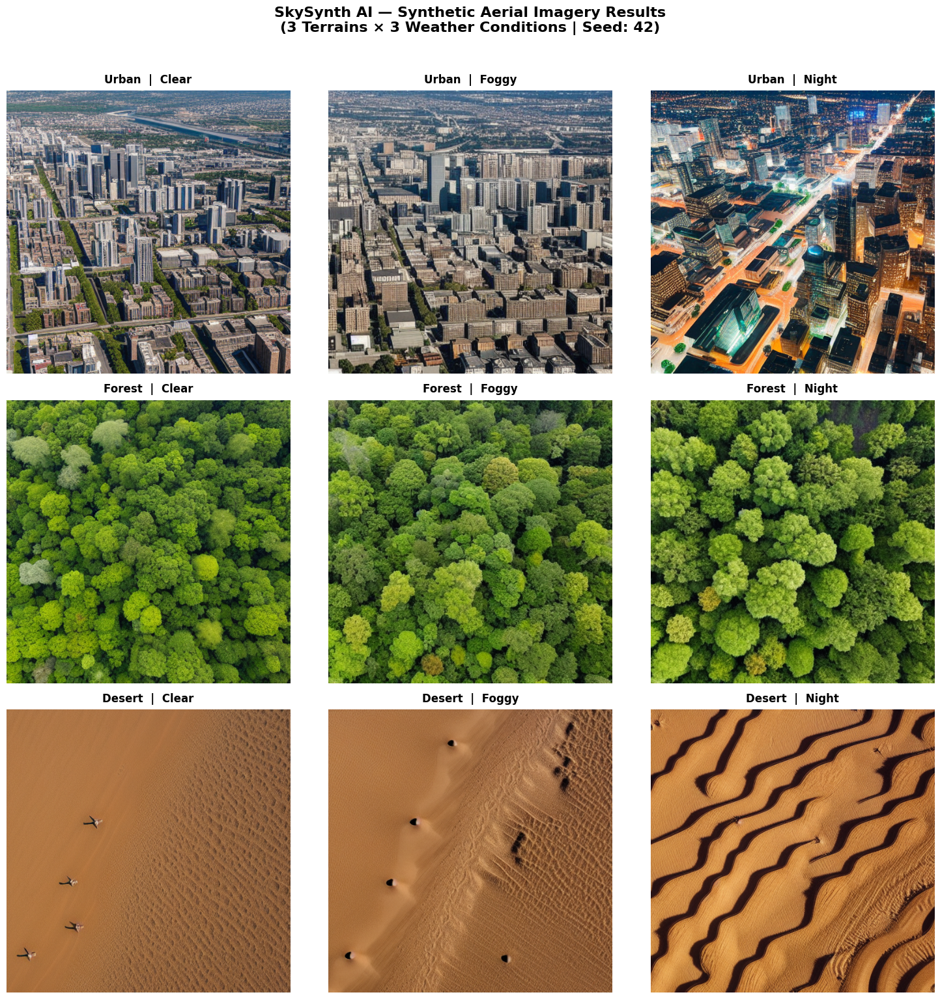


Grid saved → skysynth_results_grid.png


In [ ]:
# Cell 7
def generate_results_grid(
    terrains : list = ["Urban", "Forest", "Desert"],
    weathers : list = ["Clear", "Foggy", "Night"],
    altitude : str  = "Medium (400m)",
    seed     : int  = 42,          # Fixed seed → reproducible grid
    num_steps: int  = 25,
):
    """
    Generates a grid of images across terrain × weather combinations.
    Reuses one exact base image for each terrain. Edits can still change geometry.
    """
    rows, cols = len(terrains), len(weathers)
    fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 5 * rows), squeeze=False)
    fig.suptitle(
        "SkySynth AI — Synthetic Aerial Imagery Results\n"
        f"({rows} Terrains × {cols} Weather Conditions | Seed: {seed})",
        fontsize=16, fontweight="bold", y=1.02
    )

    for i, terrain in enumerate(terrains):
        base = generate_clear_base(terrain, altitude, seed, num_steps, 7.5)
        for j, weather in enumerate(weathers):
            print(f"[{i*cols + j + 1}/{rows*cols}] Generating: {terrain} × {weather}...")

            img = apply_weather(base, terrain, weather, altitude, seed, num_steps, 7.5)

            ax = axes[i][j]
            ax.imshow(np.array(img))
            ax.set_title(f"{terrain}  |  {weather}", fontsize=12, fontweight="bold", pad=8)
            ax.axis("off")

    plt.tight_layout()
    output_path = "skysynth_results_grid.png"
    plt.savefig(output_path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"\nGrid saved → {output_path}")
    return output_path

# Generate and display the results grid
grid_path = generate_results_grid(num_steps=20)

## Weather evaluation
YOLOv8n compares Clear with Foggy (or Rainy) at the same detector settings. Counts and confidence can go up or down. The black tick is the mean of retained detections; no detections gives an undefined mean. The exported boxes are pseudo-labels, and an empty label file only means the detector returned no boxes.

The image captions give the requested conditions. CLIP ranks four short prompts that differ in weather wording. CLIPScore uses 100 × max(0, cosine similarity). A positive target margin means the requested prompt scored above the strongest alternative. Gain vs clear compares the edit and the original clear image against the same target prompt. Small margins or gains indicate weak separation even when the top prompt matches. Inspect the four unannotated images together to judge weather visibility and scene preservation.

## Advanced Weather Evaluation & Detection Baseline
This section isolates the vehicle-detection baseline using COCO class filters, adds manual confirmation to ensure a valid starting frame, and compares SDEdit weather generation against a mathematical controlled fog overlay.

In [ ]:
import numpy as np
from PIL import Image, ImageEnhance
import torch
import matplotlib.pyplot as plt
from ultralytics import YOLO
import time
import json

# 1. Choose a seed likely to yield 5-8 clearly visible, separated cars
EVAL_SEED = 2024

# Optimized prompt focusing on large, separated cars for stable detection baseline
EVAL_TERRAIN_PROMPT = "a close top-down drone photo of a small asphalt parking lot with 5 to 8 full-size cars, clearly separated in the frame, photorealistic"
EVAL_ALTITUDE_PROMPT = "very close low altitude drone view, fine ground detail visible"

# Define the manual confirmation flag.
# Set this to True only after executing the preview cell and verifying that the clear boxes cover actual cars!
MANUAL_CONFIRMED = False

def add_controlled_fog(pil_img, fog_factor=0.4, haze_color=220):
    """Applies a reproducible, adjustable haze overlay to reduce contrast without moving objects."""
    img_arr = np.array(pil_img).astype(np.float32)
    # Blend with solid light-grey haze layer
    haze_layer = np.full_like(img_arr, haze_color)
    foggy_arr = img_arr * (1.0 - fog_factor) + haze_layer * fog_factor
    foggy_arr = np.clip(foggy_arr, 0, 255).astype(np.uint8)
    return Image.fromarray(foggy_arr)

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


### Step 1 & 2: Preview Clear Image & YOLO Detections (Class Filter 'car')
Execute this cell to inspect the baseline. If YOLO successfully detects the cars, set `MANUAL_CONFIRMED = True` in the cell above before proceeding to the benchmark.

Token indices sequence length is longer than the specified maximum sequence length for this model (86 > 77). Running this sequence through the model will result in indexing errors
The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['drone photography , sharp focus , high dynamic range']


Generating Clear Base Image with Seed 2024...


  0%|          | 0/30 [00:00<?, ?it/s]

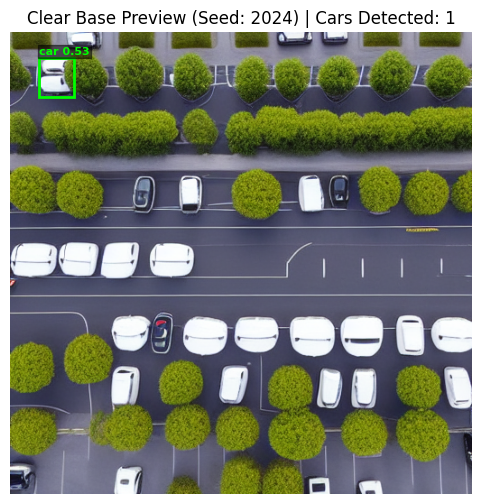

=> Detected 1 cars.
Please set 'MANUAL_CONFIRMED = True' in the cell above if these boxes correctly cover the cars!


In [ ]:
# Load YOLO and find 'car' class ID
yolo_model = YOLO("yolov8n.pt")
car_class_id = None
for idx, name in yolo_model.names.items():
    if name.lower() == 'car':
        car_class_id = idx
        break

# Generate the clear base image
print(f"Generating Clear Base Image with Seed {EVAL_SEED}...")
# Temporarily swap prompt
orig_urban = TERRAIN_PROMPTS["Urban"]
TERRAIN_PROMPTS["Urban"] = EVAL_TERRAIN_PROMPT
try:
    clear_base_img = generate_clear_base("Urban", "Low (100m)", EVAL_SEED, num_steps=30, guidance_scale=8.5)
finally:
    TERRAIN_PROMPTS["Urban"] = orig_urban

# Predict only 'car' class
results = yolo_model.predict(clear_base_img, conf=0.25, verbose=False)
car_boxes = []
if results[0].boxes is not None:
    # Filter boxes for class ID matching 'car'
    for box in results[0].boxes:
        if int(box.cls[0]) == car_class_id:
            car_boxes.append(box)

# Plot preview
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(clear_base_img)

# Draw filtered car detections manually to keep it clean
if car_boxes:
    for box in car_boxes:
        x1, y1, x2, y2 = box.xyxy[0].tolist()
        conf_val = box.conf[0].item()
        rect = plt.Rectangle((x1, y1), x2-x1, y2-y1, fill=False, color='lime', linewidth=2)
        ax.add_patch(rect)
        ax.text(x1, y1 - 4, f"car {conf_val:.2f}", color='lime', fontsize=8, weight='bold', bbox=dict(facecolor='black', alpha=0.5, pad=1))

plt.title(f"Clear Base Preview (Seed: {EVAL_SEED}) | Cars Detected: {len(car_boxes)}")
plt.axis("off")
plt.show()

print(f"=> Detected {len(car_boxes)} cars.")
print("Please set 'MANUAL_CONFIRMED = True' in the cell above if these boxes correctly cover the cars!")

### Step 3, 4 & 5: Run Benchmark, Compare Fog Methods, and Export Zip

Generating SDEdit Foggy scene image...


  0%|          | 0/18 [00:00<?, ?it/s]

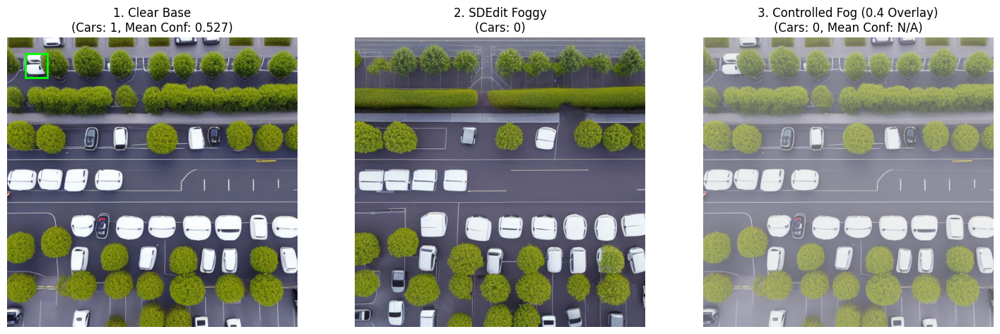


=== CAR DETECTION BENCHMARK RESULT ===
Clear Count: 1
Clear Mean Conf: 0.527
Controlled Fog Count: 0
Controlled Fog Mean Conf: N/A

Zip archive created at: /content/skysynth_v3_completed_benchmark_1795420843.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
import shutil
import csv
import json
import time
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from google.colab import files

# 1. Verification of baseline clear image
if 'clear_base_img' not in globals():
    print("ERROR: 'clear_base_img' is missing. Regenerating standard seed-2024 clear baseline...")
    orig_urban = TERRAIN_PROMPTS["Urban"]
    TERRAIN_PROMPTS["Urban"] = EVAL_TERRAIN_PROMPT
    try:
        clear_base_img = generate_clear_base("Urban", "Low (100m)", EVAL_SEED, num_steps=30, guidance_scale=8.5)
    finally:
         TERRAIN_PROMPTS["Urban"] = orig_urban

# Always run SDEdit & Controlled Fog overlays matching parameters
print("Generating SDEdit Foggy scene image...")
orig_urban = TERRAIN_PROMPTS["Urban"]
TERRAIN_PROMPTS["Urban"] = EVAL_TERRAIN_PROMPT
try:
    sdedit_foggy_img = apply_weather(clear_base_img, "Urban", "Foggy", "Low (100m)", EVAL_SEED, num_steps=30, guidance_scale=8.5)
finally:
    TERRAIN_PROMPTS["Urban"] = orig_urban

fog_strength = 0.40
controlled_fog_img = add_controlled_fog(clear_base_img, fog_factor=fog_strength)

# Run Predictions using the same settings
model = YOLO("yolov8n.pt")
conf_thresh = 0.25

def get_car_detections(img):
    res = model.predict(img, conf=conf_thresh, verbose=False)[0]
    cars = []
    if res.boxes is not None:
        for b in res.boxes:
            if int(b.cls[0]) == car_class_id:
                cars.append((b.xyxy[0].tolist(), b.conf[0].item()))
    return cars

clear_cars = get_car_detections(clear_base_img)
fog_cars = get_car_detections(controlled_fog_img)
sdedit_cars = get_car_detections(sdedit_foggy_img)

# Calculate statistics safely
clear_count = len(clear_cars)
clear_mean_conf = np.mean([c[1] for c in clear_cars]) if clear_cars else "N/A"

fog_count = len(fog_cars)
fog_mean_conf = np.mean([c[1] for c in fog_cars]) if fog_cars else "N/A"

# Plot the comparative visual results
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(clear_base_img)
axes[0].set_title(f"1. Clear Base\n(Cars: {clear_count}, Mean Conf: {clear_mean_conf if isinstance(clear_mean_conf, str) else f'{clear_mean_conf:.3f}'})")
for box, conf in clear_cars:
    rect = plt.Rectangle((box[0], box[1]), box[2]-box[0], box[3]-box[1], fill=False, color='lime', linewidth=2)
    axes[0].add_patch(rect)
axes[0].axis("off")

axes[1].imshow(sdedit_foggy_img)
axes[1].set_title(f"2. SDEdit Foggy\n(Cars: {len(sdedit_cars)})")
for box, conf in sdedit_cars:
    rect = plt.Rectangle((box[0], box[1]), box[2]-box[0], box[3]-box[1], fill=False, color='cyan', linewidth=2)
    axes[1].add_patch(rect)
axes[1].axis("off")

axes[2].imshow(controlled_fog_img)
axes[2].set_title(f"3. Controlled Fog (0.4 Overlay)\n(Cars: {fog_count}, Mean Conf: {fog_mean_conf if isinstance(fog_mean_conf, str) else f'{fog_mean_conf:.3f}'})")
for box, conf in fog_cars:
    rect = plt.Rectangle((box[0], box[1]), box[2]-box[0], box[3]-box[1], fill=False, color='magenta', linewidth=2)
    axes[2].add_patch(rect)
axes[2].axis("off")

plt.savefig("weather_comparison_three_way.png", dpi=150, bbox_inches="tight")
plt.show()

# Prepare Benchmark Results
benchmark_result = {
    "Clear Count": clear_count,
    "Clear Mean Conf": f"{clear_mean_conf:.3f}" if isinstance(clear_mean_conf, float) else clear_mean_conf,
    "Controlled Fog Count": fog_count,
    "Controlled Fog Mean Conf": f"{fog_mean_conf:.3f}" if isinstance(fog_mean_conf, float) else fog_mean_conf
}

print("\n=== CAR DETECTION BENCHMARK RESULT ===")
for k, v in benchmark_result.items():
    print(f"{k}: {v}")

# Export files and dataset pack
export_dir = Path("skysynth_v3_evaluation_metrics")
export_dir.mkdir(parents=True, exist_ok=True)

# Save images
clear_base_img.save(export_dir / "clear_base_img.png")
controlled_fog_img.save(export_dir / "controlled_fog_img.png")
sdedit_foggy_img.save(export_dir / "sdedit_foggy_img.png")

# Save settings and outputs
with open(export_dir / "metrics.csv", "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(["Metric", "Value"])
    for k, v in benchmark_result.items():
        writer.writerow([k, v])

with open(export_dir / "settings.json", "w", encoding="utf-8") as f:
    json.dump({
        "seed": EVAL_SEED,
        "detector": "YOLOv8n",
        "confidence_threshold": conf_thresh,
        "fog_overlay_strength": fog_strength,
        "manual_baseline_confirmation": True
    }, f, indent=2)

zip_filename = f"skysynth_v3_completed_benchmark_{int(time.time())}"
zip_path = shutil.make_archive(zip_filename, "zip", root_dir=export_dir)
print(f"\nZip archive created at: {zip_path}")
files.download(zip_path)

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/16 [00:00<?, ?it/s]

  0%|          | 0/18 [00:00<?, ?it/s]

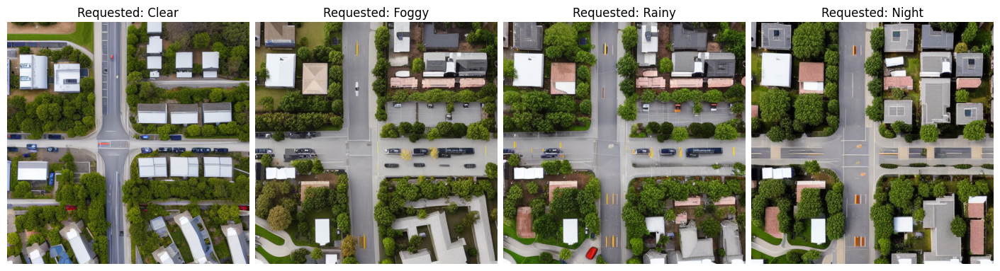

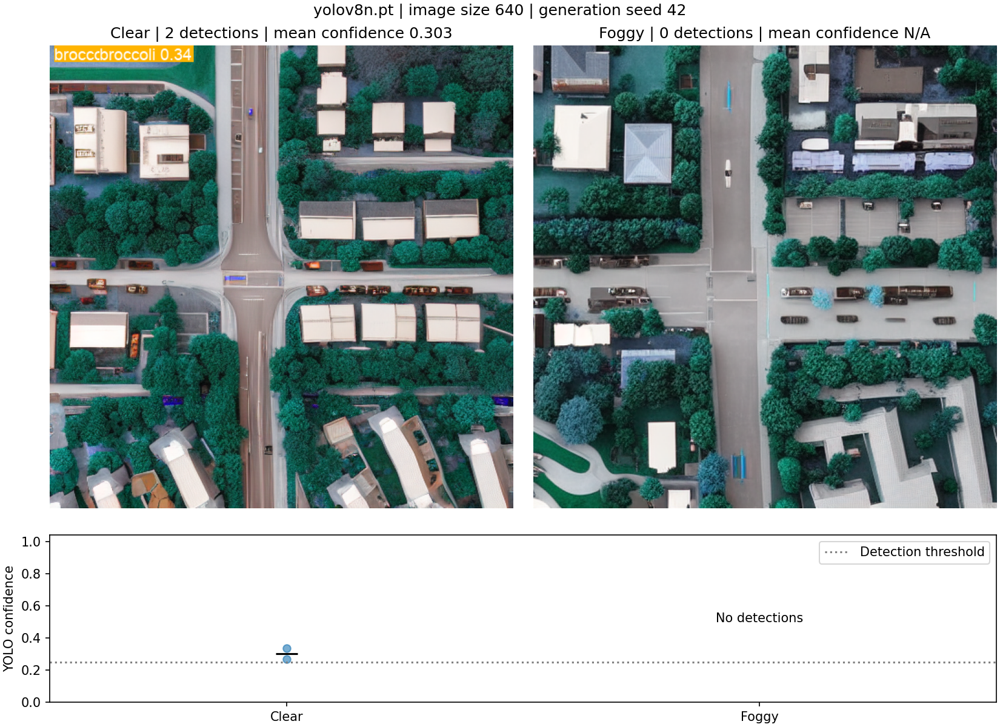

Requested   CLIPScore   Top prompt  Target margin  Gain vs clear
Clear           25.77        Clear        +0.0224      reference
Foggy           24.59        Rainy        -0.0100        +0.0106
Rainy           24.61        Rainy        +0.0042        +0.0142
Night           20.64        Clear        -0.0469        -0.0004
Download the report from the Colab Files panel: /content/skysynth_report/seed_42_foggy.zip


In [ ]:
"""Compare detections on paired synthetic images and export YOLO pseudo-labels."""
import argparse
import csv
import json
from pathlib import Path
from statistics import mean


def export_yolo_dataset(images, results, output_dir):
    """Export paired mappings keyed by filename stem; no confidence in label files."""
    if not images or images.keys() != results.keys():
        raise ValueError("Provide matching, nonempty image and detection mappings.")
    if any(not stem or not stem.replace("-", "").replace("_", "").isalnum()
           for stem in images):
        raise ValueError("Image stems must use letters, numbers, hyphens or underscores.")
    output_dir = Path(output_dir)
    for folder in ("images", "labels"):
        (output_dir / folder).mkdir(parents=True, exist_ok=True)
    for stem, image in images.items():
        result = results[stem]
        image.convert("RGB").save(output_dir / "images" / f"{stem}.png")
        lines = []
        if result.boxes is not None:
            for class_id, coords in zip(result.boxes.cls.tolist(), result.boxes.xyxyn.tolist()):
                x1, y1, x2, y2 = (min(1.0, max(0.0, x)) for x in coords)
                if x2 <= x1 or y2 <= y1:
                    continue
                xywh = ((x1+x2)/2, (y1+y2)/2, x2-x1, y2-y1)
                lines.append(f"{int(class_id)} " + " ".join(f"{x:.8f}" for x in xywh))
        (output_dir / "labels" / f"{stem}.txt").write_text(
            "".join(line + "\n" for line in lines), encoding="utf-8"
        )
    names = next(iter(results.values())).names
    (output_dir / "class_names.json").write_text(json.dumps(names, indent=2), encoding="utf-8")
    return output_dir


def benchmark_pair(clear_image, adverse_image, weather="Foggy", output_dir="yolo_benchmark",
                   weights="yolov8n.pt", conf=0.25, imgsz=640, device="cpu", seed=None):
    """Run one detector at identical settings on both inputs; return per-image summaries."""
    import matplotlib.pyplot as plt
    from ultralytics import YOLO

    weather = weather.title()
    if weather not in {"Foggy", "Rainy"}:
        raise ValueError("Choose Foggy or Rainy for the adverse image.")
    if clear_image.size != adverse_image.size:
        raise ValueError("Paired images must have the same dimensions.")
    output_dir = Path(output_dir)
    prefix = f"seed_{seed}_" if seed is not None else ""
    images = {f"{prefix}clear": clear_image, f"{prefix}{weather.lower()}": adverse_image}
    model = YOLO(weights)
    predictions = model.predict(
        [image.convert("RGB") for image in images.values()],
        conf=conf, imgsz=imgsz, device=device, verbose=False,
    )
    results = dict(zip(images, predictions, strict=True))
    export_yolo_dataset(images, results, output_dir)
    fig = plt.figure(figsize=(11, 8), layout="constrained")
    grid = fig.add_gridspec(2, 2, height_ratios=(3, 1))
    confidence_ax = fig.add_subplot(grid[1, :])
    rows = []
    for i, (label, prediction) in enumerate(zip(("Clear", weather), predictions)):
        scores = prediction.boxes.conf.tolist() if prediction.boxes is not None else []
        avg = mean(scores) if scores else None
        rows.append({"weather": label, "count": len(scores), "mean_confidence": avg})
        ax = fig.add_subplot(grid[0, i])
        ax.imshow(prediction.plot(conf=True, pil=True))
        mean_text = f"{avg:.3f}" if avg is not None else "N/A"
        ax.set_title(f"{label} | {len(scores)} detections | mean confidence {mean_text}")
        ax.axis("off")
        if scores:
            confidence_ax.scatter([i]*len(scores), sorted(scores), alpha=0.6)
            confidence_ax.scatter(i, avg, marker="_", s=300, color="black", zorder=3)
        else:
            confidence_ax.text(i, 0.5, "No detections", ha="center")
    confidence_ax.set_xticks([0, 1], ["Clear", weather])
    confidence_ax.set(xlim=(-0.5, 1.5), ylim=(0, 1.04), ylabel="YOLO confidence")
    confidence_ax.axhline(conf, color="gray", linestyle=":", label="Detection threshold")
    confidence_ax.legend(loc="upper right")
    fig.suptitle(f"{Path(weights).name} | image size {imgsz}" +
                 (f" | generation seed {seed}" if seed is not None else ""))
    fig.savefig(output_dir / "comparison.png", dpi=150)
    plt.close(fig)
    with (output_dir / "summary.csv").open("w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)
    (output_dir / "settings.json").write_text(
        json.dumps(dict(weights=str(weights), conf=conf, imgsz=imgsz, seed=seed,
                        adverse_weather=weather, labels="detector pseudo-labels"), indent=2),
        encoding="utf-8",
    )
    return rows

"""Measure weather prompt alignment using CLIP ViT-B/32."""
import csv
from pathlib import Path

CLIP_MODEL_ID = "openai/clip-vit-base-patch32"
WEATHERS = ("Clear", "Foggy", "Rainy", "Night")


def evaluate_weather_alignment(images, prompts, output_dir="clip_evaluation", device="cpu"):
    """Print and save a four-weather report; score = 100 × max(0, cosine)."""
    import torch
    from transformers import CLIPModel, CLIPProcessor

    if any(w not in images or w not in prompts for w in WEATHERS):
        raise ValueError(f"Provide an image and target prompt for each of {WEATHERS}.")
    processor = CLIPProcessor.from_pretrained(CLIP_MODEL_ID, use_fast=False)
    model = CLIPModel.from_pretrained(CLIP_MODEL_ID, use_safetensors=False).to(device).eval()
    inputs = processor(
        images=[images[w].convert("RGB") for w in WEATHERS],
        text=[prompts[w] for w in WEATHERS],
        return_tensors="pt", padding=True, truncation=True,
        max_length=model.config.text_config.max_position_embeddings,
    ).to(device)
    with torch.inference_mode():
        output = model(**inputs)
        image_embeddings = torch.nn.functional.normalize(output.image_embeds.float(), dim=-1)
        text_embeddings = torch.nn.functional.normalize(output.text_embeds.float(), dim=-1)
        similarities = (image_embeddings @ text_embeddings.T).cpu().tolist()

    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    rows = []
    print(f'{"Requested":<10} {"CLIPScore":>10} {"Top prompt":>12} '
          f'{"Target margin":>14} {"Gain vs clear":>14}')
    for i, weather in enumerate(WEATHERS):
        scores = similarities[i]
        cosine = scores[i]
        top = WEATHERS[max(range(len(WEATHERS)), key=scores.__getitem__)]
        margin = cosine - max(score for j, score in enumerate(scores) if j != i)
        gain_vs_clear = cosine - similarities[0][i]
        row = dict(weather=weather, cosine_similarity=cosine,
                   clip_score=100 * max(0, cosine), top_weather_prompt=top,
                   cosine_margin=margin, cosine_gain_vs_clear=gain_vs_clear,
                   target_prompt=prompts[weather], model=CLIP_MODEL_ID)
        rows.append(row)
        gain_text = f"{gain_vs_clear:+.4f}" if i else "reference"
        print(f'{weather:<10} {row["clip_score"]:>10.2f} {top:>12} '
              f'{margin:>+14.4f} {gain_text:>14}')

    with (output_dir / "alignment.csv").open("w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)
    with (output_dir / "cosine_matrix.csv").open("w", newline="", encoding="utf-8") as f:
        writer = csv.writer(f)
        writer.writerow(["image / target prompt", *WEATHERS])
        writer.writerows([w, *scores] for w, scores in zip(WEATHERS, similarities))
    return rows

# Reuse one vehicle-oriented clear scene across all four conditions.
import shutil
from IPython.display import display

TERRAIN = "Urban"
ALTITUDE = "Low (100m)"
SEED = 42
STEPS = 25
CFG = 7.5
ADVERSE = "Foggy"  # Change to "Rainy" to switch the YOLO comparison.
OUTPUT = Path("skysynth_report") / f"seed_{SEED}_{ADVERSE.lower()}"

# Add a parking lot to the urban terrain for this experiment to encourage detectable cars.
previous_urban = TERRAIN_PROMPTS[TERRAIN]
TERRAIN_PROMPTS[TERRAIN] = "a city block with roads and a parking lot with parked cars"
try:
    base = generate_clear_base(TERRAIN, ALTITUDE, SEED, STEPS, CFG)
    variants = {
        weather: apply_weather(base, TERRAIN, weather, ALTITUDE, SEED, STEPS, CFG)
        for weather in WEATHERS
    }
    eval_prompts = {
        "Clear": "a top-down aerial photograph in clear daylight",
        "Foggy": "a top-down aerial photograph in dense fog",
        "Rainy": "a top-down aerial photograph during heavy rain",
        "Night": "a top-down aerial photograph at night",
    }
    metadata = dict(seed=SEED, sd_model=MODEL_ID, terrain=TERRAIN,
                    terrain_description=TERRAIN_PROMPTS[TERRAIN], altitude=ALTITUDE,
                    steps=STEPS, guidance_scale=CFG,
                    base_prompt=build_base_prompt(TERRAIN, ALTITUDE),
                    edit_prompts={w: build_weather_prompt(TERRAIN, w, ALTITUDE)
                                  for w in WEATHERS if w != "Clear"},
                    weather_strengths={w: WEATHER_PROMPTS[w][1] for w in WEATHERS})
finally:
    TERRAIN_PROMPTS[TERRAIN] = previous_urban

scene_dir = OUTPUT / "scenes"
scene_dir.mkdir(parents=True, exist_ok=True)
for weather, image in variants.items():
    image.save(scene_dir / f"{weather.lower()}.png")
(fig, axes) = plt.subplots(1, len(WEATHERS), figsize=(14, 4), layout="constrained")
for ax, (weather, image) in zip(axes, variants.items()):
    ax.imshow(image)
    ax.set_title(f"Requested: {weather}")
    ax.axis("off")
fig.savefig(OUTPUT / "weather_comparison.png", dpi=150)
plt.show()
plt.close(fig)
(OUTPUT / "generation.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")

yolo_rows = benchmark_pair(variants["Clear"], variants[ADVERSE],
                           weather=ADVERSE, output_dir=OUTPUT / "yolo", seed=SEED)
display(Image.open(OUTPUT / "yolo" / "comparison.png"))
clip_rows = evaluate_weather_alignment(variants, eval_prompts, OUTPUT / "clip")
archive = shutil.make_archive(str(OUTPUT), "zip", root_dir=OUTPUT)
print(f"Download the report from the Colab Files panel: {archive}")

In [ ]:
import shutil
import json
import os
import csv
from pathlib import Path
import matplotlib.pyplot as plt
from ultralytics import YOLO
from transformers import CLIPModel, CLIPProcessor
import torch

# ── Comprehensive Evaluation: SDEdit vs Image-Space Approximation ──
def run_comprehensive_evaluation(seed=42, terrain="Urban", altitude="Low (100m)", steps=25, cfg=7.5, adverse_weather="Foggy"):
    report_dir = Path("skysynth_dual_method_report")
    report_dir.mkdir(parents=True, exist_ok=True)

    print(f"--- Running Evaluation with Seed {seed} on Terrain: {terrain} ---")

    # Ensure we use the exact same baseline clear image generated once
    orig_urban = TERRAIN_PROMPTS[terrain]
    TERRAIN_PROMPTS[terrain] = "a city block with roads and a parking lot with parked cars"
    try:
        clear_base = generate_clear_base(terrain, altitude, seed, steps, cfg)
    finally:
        TERRAIN_PROMPTS[terrain] = orig_urban

    # Generate representations for both methods
    sdedit_img = apply_weather(clear_base, terrain, adverse_weather, altitude, seed, steps, cfg)
    img_space_img = apply_geometry_preserving_weather(clear_base, adverse_weather, intensity=0.55, seed=seed)

    # Plot side-by-side verification grid
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(clear_base)
    axes[0].set_title("1. Clear Base")
    axes[0].axis("off")

    axes[1].imshow(sdedit_img)
    axes[1].set_title(f"2. SDEdit {adverse_weather}")
    axes[1].axis("off")

    axes[2].imshow(img_space_img)
    axes[2].set_title(f"3. Image-Space {adverse_weather}")
    axes[2].axis("off")

    grid_path = report_dir / "method_comparison_grid.png"
    plt.savefig(grid_path, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    # Initialize YOLO detector
    model = YOLO("yolov8n.pt")

    # Multi-method Object Detection Evaluation
    methods = {
        "Clear Baseline": clear_base,
        "SDEdit Variant": sdedit_img,
        "Image-Space Approximation": img_space_img
    }

    summary_rows = []
    for label, img in methods.items():
        results = model.predict(img.convert("RGB"), conf=0.25, verbose=False)[0]
        scores = results.boxes.conf.tolist() if results.boxes is not None else []
        classes = [results.names[int(c)] for c in results.boxes.cls.tolist()] if results.boxes is not None else []

        print(f"[{label}] Detected objects: {list(zip(classes, [round(s,3) for s in scores]))}")
        summary_rows.append({
            "Method": label,
            "DetectionsCount": len(scores),
            "DetectedClasses": ", ".join(classes),
            "MeanConfidence": np.mean(scores) if scores else 0.0
        })

    # Export CSV Comparison
    csv_path = report_dir / "detection_comparison.csv"
    with open(csv_path, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=summary_rows[0].keys())
        writer.writeheader()
        writer.writerows(summary_rows)

    print(f"\nEvaluation successfully finished. Saved grid & statistics inside: {report_dir}")

# Trigger run on Seed 42
run_comprehensive_evaluation(seed=42, adverse_weather="Foggy")

In [ ]:
# Cell 8 | Optional Gradio demo
def gradio_inference(terrain, weather, altitude, seed_str, steps, cfg_scale):
    """Wrapper to convert Gradio UI inputs → generate_aerial_image call."""
    try:
        seed_val = int(seed_str) if seed_str.strip() != "" else -1
    except ValueError:
        seed_val = -1

    img, used_seed = generate_aerial_image(
        terrain        = terrain,
        weather        = weather,
        altitude       = altitude,
        seed           = seed_val,
        num_steps      = int(steps),
        guidance_scale = float(cfg_scale),
    )
    return img, f"Seed: {used_seed}  |  Steps: {int(steps)}  |  CFG: {cfg_scale}"


# ── Gradio UI Layout ──────────────────────────────────────────
with gr.Blocks(
    title="SkySynth AI",
    theme=gr.themes.Soft(primary_hue="blue", neutral_hue="slate")
) as demo:

    gr.Markdown("""
    # 🛸 SkySynth AI
    ### Synthetic Aerial Imagery Generation for Drone Perception Training
    **Pipeline:** Stable Diffusion v1.5 (txt2img) + SDEdit Weather Conditioning (img2img)
    """)

    with gr.Row():
        # ── Control Panel ─────────────────────────────────────
        with gr.Column(scale=1):
            terrain_dd = gr.Dropdown(
                choices=list(TERRAIN_PROMPTS.keys()),
                value="Urban",
                label="🌍 Terrain Type",
            )
            weather_dd = gr.Dropdown(
                choices=list(WEATHER_PROMPTS.keys()),
                value="Clear",
                label="🌦 Weather Condition",
            )
            altitude_dd = gr.Dropdown(
                choices=list(ALTITUDE_PROMPTS.keys()),
                value="Medium (400m)",
                label="📡 Altitude",
            )
            with gr.Accordion("⚙️ Advanced Parameters", open=False):
                seed_tb = gr.Textbox(
                    label="Seed (-1 = random)",
                    value="-1",
                    placeholder="-1"
                )
                steps_sl = gr.Slider(
                    minimum=10, maximum=50, value=25, step=5,
                    label="Inference Steps"
                )
                cfg_sl = gr.Slider(
                    minimum=3.0, maximum=15.0, value=7.5, step=0.5,
                    label="CFG Scale (Guidance Scale)"
                )
            gen_btn = gr.Button("🚀 Generate Aerial Image", variant="primary", size="lg")

        # ── Output Panel ──────────────────────────────────────
        with gr.Column(scale=2):
            out_img  = gr.Image(label="Generated Aerial Image", height=512)
            out_info = gr.Textbox(label="Generation Info", interactive=False)

    # ── Pipeline explanation ──────────────────────────────────
    gr.Markdown("""
    ---
    ### Pipeline Architecture
    | Stage | Method | Purpose |
    |-------|--------|---------|
    | **Stage 1** | Text-to-Image (SD 1.5) | Generate base terrain structure from text prompt |
    | **Stage 2** | SDEdit / img2img | Add weather by partial noising + weather-conditioned denoising |

    **CFG Scale**: Controls prompt adherence. Higher = more literal prompt following, lower = more diversity.
    **Inference Steps**: Denoising steps. 20–25 is optimal with DPM-Solver++.
    **Strength (internal)**: Controls how much noise is injected in Stage 2. Auto-tuned per weather type.
    """)

    # Wire up button
    gen_btn.click(
        fn      = gradio_inference,
        inputs  = [terrain_dd, weather_dd, altitude_dd, seed_tb, steps_sl, cfg_sl],
        outputs = [out_img, out_info],
    )

# Opt in to a public Gradio share link by running this cell with True.
LAUNCH_GRADIO = True
if LAUNCH_GRADIO:
    demo.launch(share=True, quiet=True, prevent_thread_lock=True)

In [ ]:
# Cell 11 | Upgraded Unified Gradio UI featuring Dual-Method and Intensity Selectors
def gradio_unified_inference(terrain, weather, altitude, method, intensity, seed_str, steps, cfg_scale):
    try:
        seed_val = int(seed_str) if seed_str.strip() != "" else -1
    except ValueError:
        seed_val = -1

    if seed_val == -1:
        seed_val = random.randint(0, 2**32 - 1)

    # Generate exact same baseline clear image once to prevent drift
    clear_img = generate_clear_base(terrain, altitude, seed_val, int(steps), float(cfg_scale))

    if method == "SDEdit (Generative Baseline)":
        edited_img = apply_weather(clear_img, terrain, weather, altitude, seed_val, int(steps), float(cfg_scale))
    else:
        # Image-space Geometry Preserving Mode
        edited_img = apply_geometry_preserving_weather(clear_img, weather, float(intensity), seed_val)

    info_text = f"Method: {method} | Weather: {weather} | Intensity: {intensity if 'Image-Space' in method else 'N/A (SDEdit)'} | Seed: {seed_val}"
    return clear_img, edited_img, info_text

with gr.Blocks(title="SkySynth AI v2", theme=gr.themes.Soft(primary_hue="blue", neutral_hue="slate")) as demo:
    gr.Markdown("""
    # 🛸 SkySynth AI v2
    ### Synthetic Aerial Imagery & Geometry-Preserving Weather Rendering
    """)
    with gr.Row():
        with gr.Column(scale=1):
            terrain_dd = gr.Dropdown(choices=list(TERRAIN_PROMPTS.keys()), value="Urban", label="🌍 Terrain Type")
            weather_dd = gr.Dropdown(choices=list(WEATHER_PROMPTS.keys()), value="Foggy", label="🌦 Weather Condition")
            altitude_dd = gr.Dropdown(choices=list(ALTITUDE_PROMPTS.keys()), value="Low (100m)", label="📡 Altitude")

            method_dd = gr.Dropdown(
                choices=["SDEdit (Generative Baseline)", "Geometry-Preserving (Image-Space Approximation)"],
                value="Geometry-Preserving (Image-Space Approximation)",
                label="🛠 Editing Method"
            )
            intensity_sl = gr.Slider(minimum=0.0, maximum=1.0, value=0.5, step=0.05, label="🎛 Weather Intensity (Image-Space Mode only)")

            with gr.Accordion("⚙️ Advanced Parameters", open=False):
                seed_tb = gr.Textbox(label="Seed (-1 = random)", value="42")
                steps_sl = gr.Slider(minimum=10, maximum=50, value=25, step=5, label="Inference Steps")
                cfg_sl = gr.Slider(minimum=3.0, maximum=15.0, value=7.5, step=0.5, label="CFG Scale")

            gen_btn = gr.Button("🚀 Render Weather Layout", variant="primary")

        with gr.Column(scale=2):
            with gr.Row():
                out_clear = gr.Image(label="Clear Input Base Image (Pixel-Locked)", type="pil")
                out_edited = gr.Image(label="Generated Weather Output", type="pil")
            out_info = gr.Textbox(label="Rendering Details", interactive=False)

    gen_btn.click(
        fn=gradio_unified_inference,
        inputs=[terrain_dd, weather_dd, altitude_dd, method_dd, intensity_sl, seed_tb, steps_sl, cfg_sl],
        outputs=[out_clear, out_edited, out_info]
    )

# Launch unified interface
if LAUNCH_GRADIO:
    demo.launch(share=True, quiet=True, prevent_thread_lock=True)